HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

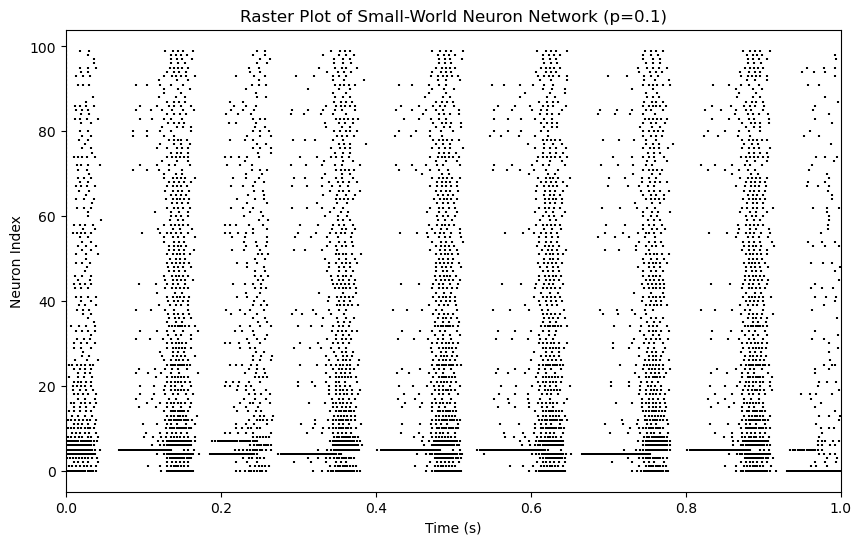

In [ ]:
# https://arxiv.org/abs/2304.08281

import numpy as np
import nengo
import networkx as nx
import matplotlib.pyplot as plt

# network
N = 100         # number of neurons
#k = 4           # Each node is connected to k nearest neighbors in a ring
m = 3           # Number of edges to attach from a new node to existing nodes
p = 0.1         # Rewiring probability (0 = regular ring, 1 = completely random)
g_coupling = 0.5  # Strength of synaptic connections

# --- 2. Generate Small-World Topology ---
# Create a Watts-Strogatz small-world graph
graph = nx.watts_strogatz_graph(n=N, k=k, p=p, seed=42)
graph = nx.barabasi_albert_graph(n=N, m=m, seed=42)

# Convert the graph into an adjacency matrix (N x N)
adjacency_matrix = nx.to_numpy_array(graph)

# Scale by our coupling strength to create the weight matrix
# (We assume excitatory-like coupling for synchronization)
weights = adjacency_matrix * g_coupling

# --- 3. Build the Nengo Model ---
#model = nengo.Network(label="Small-World Synchronization")
model = nengo.Network(label="Scale-Free Synchronization")

# with model:
#     # Create a population of 100 LIF neurons
#     # We set encoders to 1 so they all respond similarly to input/coupling
#     neurons = nengo.Ensemble(
#         n_neurons=N,
#         dimensions=1,
#         neuron_type=nengo.Izhikevich(), #nengo.LIF(tau_rc=0.02, tau_ref=0.002),
#         encoders=np.ones((N, 1)),
#         intercepts=np.zeros(N) #np.random.uniform(-0.05, 0.05, N) # Uniform firing thresholds
#     )
    
#     # Provide a constant background current to kick them into an active firing state
#     bg_input = nengo.Node(1.4)
#     nengo.Connection(bg_input, neurons.neurons, transform=g_coupling*np.ones((N, 1)))
    
#     # Connect the neurons to themselves using our small-world weight matrix
#     # We use 'neurons.neurons' to connect directly at the synapse/current level
#     nengo.Connection(
#         neurons.neurons, 
#         neurons.neurons, 
#         transform=weights, 
#         synapse=0.01  # 10ms synaptic time constant
#     )
    
#     # Probe the spikes to analyze synchronization
#     #spike_probe = nengo.Probe(neurons.neurons, 'spikes')
#     spike_probe = nengo.Probe(neurons.neurons, 'output')



with model:
    # CRITICAL FIX: We explicitly set max_rates and intercepts 
    # so every neuron shares the exact same baseline speed (50 Hz).
    neurons = nengo.Ensemble(
        n_neurons=N,
        dimensions=1,
        neuron_type=nengo.Izhikevich(), 
        encoders=np.ones((N, 1)),
        intercepts=np.zeros(N),          # Identical thresholds
        max_rates=np.ones(N) * 5         # Identical baseline speeds (50 Hz)
    )
    
    # Background drive to push them to actively fire
    bg_input = nengo.Node(0.5)
    nengo.Connection(bg_input, neurons.neurons, transform=np.ones((N, 1)))
    
    # Recurrent scale-free network connections
    # We increase g_coupling slightly to ensure the hubs dominate the rhythm
    nengo.Connection(
        neurons.neurons, 
        neurons.neurons, 
        transform=adjacency_matrix * 0.15, # Replaced g_coupling variable with inline 0.15
        synapse=0.01  
    )
    
    spike_probe = nengo.Probe(neurons.neurons, 'output')

# --- 4. Run the Simulation ---
with nengo.Simulator(model) as sim:
    sim.run(1.0)  # Run for 1 second

# --- 5. Plot the Raster Plot ---
plt.figure(figsize=(10, 6))
# Find indices where spikes occurred
time_indices, neuron_indices = np.where(sim.data[spike_probe] > 0)
# Convert time indices to actual seconds (Nengo default dt = 0.001s)
spike_times = time_indices * sim.dt

plt.scatter(spike_times, neuron_indices, s=2, color='black', marker='|')
plt.title(f"Raster Plot of Small-World Neuron Network (p={p})")
plt.xlabel("Time (s)")
plt.ylabel("Neuron Index")
plt.xlim(0, 1.0)
plt.show()